# Lab 8B — Text-to-Audio Retrieval with CLAP
### AIML ZG527 — Audio Analysis
**Authored by:** Seetha Parameswaran, BITS Pilani WILP

Lab 8A built a working retrieval system with one hard limit: to find a sound, the user had
to **already have a sound**. YAMNet maps audio to a vector, but it has no way to place the
*sentence* "a siren passing by" into that same space — so searching an archive with **words** was impossible.

**CLAP** (Contrastive Language–Audio Pretraining) removes that limit. It trains two separate encoders — one for audio, one for text — to land in a **single shared space**, joined only by a contrastive loss. Once "a dog barking" (text) sits near an actual bark clip (audio), search by description becomes the same nearest-neighbour geometry as before. This lab builds that, examines the training signal that makes it work, and then deliberately breaks it.

**What CLAP unlocks over 8A:**

| Capability | 8A (YAMNet) | 8B (CLAP) |
|------------|-------------|-----------|
| Audio → Audio search | ✓ | ✓ (and more semantic) |
| **Text → Audio search** | ✗ | ✓ |
| Zero-shot classification | ✗ | ✓ |
| Open vocabulary (any sentence) | ✗ | ✓ |

---
### Learning Objectives
- Embed audio and text into a shared space using CLAP's two towers, called independently
- Retrieve audio clips from natural-language **text queries**
- Build and read the N×N similarity matrix — positives on the diagonal, free negatives off it
- Compute the contrastive loss and see how **temperature** controls the penalty on near-misses
- Perform **zero-shot classification** with prompt templates, and measure prompt sensitivity
- Identify CLAP's structural blind spots: order, counting, and negation (compositionality)

---
### Setup and Import Libraries

`!pip install librosa transformers pandas matplotlib scikit-learn faiss-cpu --break-system-packages`

### Dataset: UrbanSound8K
Same corpus as Lab 6A, **folds 1–2 only**, so the CLAP-vs-YAMNet comparison is fair. CLAP runs at 48 kHz, so embedding is slower than 6A — budget ~10–15 min on CPU (or set `MAX_CLIPS = 400`).

`> `UrbanSound8K.csv` and the `fold1/ … fold10/` directories sit directly under the dataset root.`

## 0. Setup

In [1]:
# If needed (uncomment):
# !pip install transformers faiss-cpu
import os, time, warnings
import numpy as np
import pandas as pd
import librosa
import matplotlib.pyplot as plt
import torch
from transformers import ClapModel, ClapProcessor
warnings.filterwarnings("ignore")
np.random.seed(0)
torch.set_grad_enabled(False)          # inference only
try:    
    import faiss    
    HAS_FAISS = True
except ImportError:    
    HAS_FAISS = False
        
DATA_ROOT = "/home/seetha/PythonScriptsCourses/PythonScriptsCourses/Audio Analysis/Data/UrbanSound8k"
FOLDS     = [1, 2]
SR        = 48000                      # CLAP expects 48 kHz
MAX_CLIPS = 800
print("FAISS available:", HAS_FAISS)

2026-07-16 15:17:51.779905: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory
2026-07-16 15:17:51.779936: I tensorflow/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if you do not have a GPU set up on your machine.


FAISS available: True


## 1. Load CLAP — and look at what you get

Note carefully: **two separate towers**. They share no weights. The only thing that ever joined them was the loss, during training. At inference they can be called independently — on different machines, at different times, if you like.

In [2]:
model = ClapModel.from_pretrained("laion/clap-htsat-unfused").eval()
processor = ClapProcessor.from_pretrained("laion/clap-htsat-unfused")
n_audio = sum(p.numel() for p in model.audio_model.parameters())
n_text  = sum(p.numel() for p in model.text_model.parameters())

print(f"Audio tower (HTSAT)  : {n_audio/1e6:.1f} M params")
print(f"Text tower (RoBERTa) : {n_text/1e6:.1f} M params")
print(f"Shared space dim d   : {model.config.projection_dim}")
print()
print("Two towers. One shared space. Joined only by the loss.")

Audio tower (HTSAT)  : 27.5 M params
Text tower (RoBERTa) : 124.6 M params
Shared space dim d   : 512

Two towers. One shared space. Joined only by the loss.


## 2. Re-embed the corpus 

This is the point the slides made about **changing the encoder**: a new encoder defines a *different vector space*. The YAMNet vectors cannot be compared with CLAP vectors — their axes mean different things. There is no partial upgrade. The whole corpus must be re-encoded.

In [3]:
def l2_normalize(X):
    return X / (np.linalg.norm(X, axis=1, keepdims=True) + 1e-9)


def embed_audio(paths, batch_size=8):
    """Corpus side: run the AUDIO tower."""
    vecs = []
    for i in range(0, len(paths), batch_size):
        batch = []
        for p in paths[i:i+batch_size]:
            wav, _ = librosa.load(p, sr=SR, mono=True)
            batch.append(wav)
        # --- these three lines are OUTSIDE the inner loop, once per batch ---
        inputs = processor(audios=batch, sampling_rate=SR, return_tensors="pt", padding=True)
        v = model.get_audio_features(**inputs).numpy()
        vecs.append(v)
    return l2_normalize(np.vstack(vecs).astype("float32"))


def embed_text(texts):
    """Query side: run the TEXT tower. Note this never touches the audio tower."""
    inputs = processor(text=texts, return_tensors="pt", padding=True)
    v = model.get_text_features(**inputs).numpy()
    return l2_normalize(v.astype("float32"))
        
# Sanity check: both towers land in the SAME space, so the dot product is defined.
a = embed_text(["a dog barking"])
b = embed_text(["a siren wailing"])
print("text vec shape:", a.shape)
print("sim(dog, siren) =", float(a @ b.T))   # a meaningful number, not a coincidence

text vec shape: (1, 512)
sim(dog, siren) = 0.4667004346847534


In [4]:
MAX_CLIPS = 400

# 1. meta
meta = pd.read_csv(os.path.join(DATA_ROOT, "UrbanSound8K.csv"))
meta = meta[meta["fold"].isin(FOLDS)].reset_index(drop=True)
if MAX_CLIPS:
    meta = meta.sample(n=min(MAX_CLIPS, len(meta)), random_state=0).reset_index(drop=True)

meta["path"] = meta.apply(
    lambda r: os.path.join(DATA_ROOT, f"fold{r['fold']}", r["slice_file_name"]), axis=1)
labels    = meta["class"].values
label_ids = meta["classID"].values
CLASSES   = sorted(meta["class"].unique())

# 2. embed  (must equal meta rows)
t0 = time.time()
E = embed_audio(list(meta["path"]))
print(f"Re-embedded {E.shape[0]} clips with CLAP in {time.time()-t0:.1f}s")
print("Embedding matrix E:", E.shape)

huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)
huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)
huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)
huggingface/tokenizers: The 

Re-embedded 400 clips with CLAP in 125.2s
Embedding matrix E: (400, 512)


In [5]:
# 3.Build the index 
d = E.shape[1]

if HAS_FAISS:    
    index = faiss.IndexFlatIP(E.shape[1])
    index.reset()
    index.add(E)
    
    def search(qvec, k=5):        
        s, i = index.search(qvec.reshape(1, -1), k)        
        return i[0], s[0]
else:    
    def search(qvec, k=5):        
        s = E @ qvec        
        i = np.argsort(-s)[:k]        
        return i, s[i]
    
print(f"Index built over {E.shape[0]} CLAP vectors.")

# 4. verify
print("FINAL:", len(meta), E.shape[0], len(labels), index.ntotal) 
print("all four agree ✓") 

Index built over 400 CLAP vectors.
FINAL: 400 400 400 400
all four agree ✓


## 3. The payoff — query with words
The user supplies **a sentence**. No audio. This is what Lab 6A could not do at all.

In [6]:
def text_query(sentence, k=5):
    q = embed_text([sentence])[0]          # TEXT tower -> one vector in the shared space
    ids, scores = search(q, k)
    print(f'QUERY: "{sentence}"')
    print(f"{'rank':<6}{'class (ground truth)':<22}{'cosine':<8}{'file'}")
    for r, (i, s) in enumerate(zip(ids, scores)):
        if i < 0:                          # FAISS pads with -1 when < k results exist
            continue
        print(f"{r+1:<6}{labels[i]:<22}{s:<8.3f}{meta.loc[i,'slice_file_name']}")
    print()
    
text_query("a dog barking")
text_query("a siren passing by")
text_query("children playing outside")
text_query("someone drilling into a wall")

QUERY: "a dog barking"
rank  class (ground truth)  cosine  file
1     dog_bark              0.594   197073-3-3-0.wav
2     dog_bark              0.591   74495-3-0-1.wav
3     dog_bark              0.585   179096-3-0-10.wav
4     dog_bark              0.577   101415-3-0-8.wav
5     dog_bark              0.574   193394-3-0-4.wav

QUERY: "a siren passing by"
rank  class (ground truth)  cosine  file
1     siren                 0.585   102871-8-0-14.wav
2     siren                 0.584   102871-8-0-1.wav
3     siren                 0.574   91396-8-0-3.wav
4     siren                 0.565   102871-8-0-5.wav
5     siren                 0.564   118279-8-0-3.wav

QUERY: "children playing outside"
rank  class (ground truth)  cosine  file
1     children_playing      0.638   138031-2-0-28.wav
2     children_playing      0.503   138031-2-0-47.wav
3     children_playing      0.446   192269-2-0-18.wav
4     children_playing      0.421   160009-2-0-22.wav
5     children_playing      0.420   84359-2-

In [7]:
q = embed_text(["a dog barking"])[0]
scores = E @ q
top = np.argsort(-scores)[:5]
print("argsort top-5 ids :", top)
print("their scores      :", scores[top].round(3))
print("their classes     :", labels[top])
print()
ids, sc = search(q, 5)
print("search() top-5 ids:", ids)
print("search() scores   :", sc.round(3))

argsort top-5 ids : [313 191 175  22 254]
their scores      : [0.594 0.591 0.585 0.577 0.574]
their classes     : ['dog_bark' 'dog_bark' 'dog_bark' 'dog_bark' 'dog_bark']

search() top-5 ids: [313 191 175  22 254]
search() scores   : [0.594 0.591 0.585 0.577 0.574]


**Note what just happened.** 
The word *"drilling"* is not a class we trained anything on here — CLAP was never fine-tuned on UrbanSound8K. The vocabulary is **open**. Any English sentence becomes a query. Now try a query with **no matching class at all**, and watch it degrade gracefully rather than fail:

In [8]:
text_query("a violin playing a slow melody")   # no such class in UrbanSound8K

QUERY: "a violin playing a slow melody"
rank  class (ground truth)  cosine  file
1     street_music          0.546   194841-9-0-178.wav
2     street_music          0.526   194841-9-0-130.wav
3     street_music          0.491   139951-9-0-33.wav
4     street_music          0.484   149254-9-0-25.wav
5     car_horn              0.483   72567-1-5-0.wav



## 4. Where the training signal comes from — the N x N matrix

The slides claimed: take a batch of N (audio, caption) pairs; the **diagonal** is the positives, and everything **off-diagonal** is a free negative. Let us build that matrix and look at it.

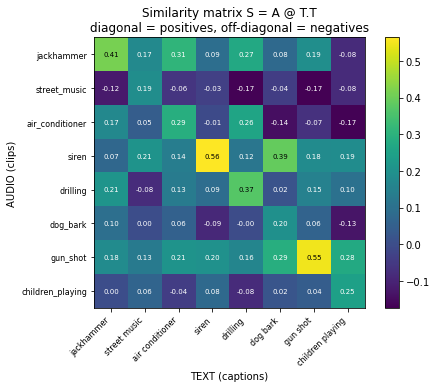

Diagonal is the argmax of its row in 8/8 rows.


In [9]:
# Take one clip from each of 8 classes, and write its "caption"
batch = meta.groupby("class").head(1).head(8).reset_index(drop=True)
captions = [f"the sound of {c.replace('_', ' ')}" for c in batch["class"]]

A = embed_audio(list(batch["path"]))     # audio tower
T = embed_text(captions)                 # text tower
S = A @ T.T                              # N x N similarity matrix

fig, ax = plt.subplots(figsize=(7, 5.5))
im = ax.imshow(S, cmap="viridis")
ax.set_xticks(range(len(captions)))
ax.set_xticklabels([c.replace("the sound of ", "") for c in captions],
                   rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(len(batch)))
ax.set_yticklabels(batch["class"], fontsize=8)
ax.set_xlabel("TEXT (captions)")
ax.set_ylabel("AUDIO (clips)")
ax.set_title("Similarity matrix S = A @ T.T\ndiagonal = positives, off-diagonal = negatives")

for i in range(len(batch)):
    for j in range(len(captions)):
        ax.text(j, i, f"{S[i,j]:.2f}", ha="center", va="center",
                color="white" if S[i, j] < S.max()*0.6 else "black", fontsize=7)

plt.colorbar(im)          # OUTSIDE both loops
plt.tight_layout()
plt.show()

print(f"Diagonal is the argmax of its row in "
      f"{(S.argmax(axis=1) == np.arange(len(S))).sum()}/{len(S)} rows.")

**Read the matrix.** The diagonal should dominate each row. Where it does not, CLAP is confusing two classes — and those confusions are informative (jackhammer vs drilling,say). Crucially: **nobody labelled these negatives.** They came free, from the batch. That is the whole economy of contrastive learning — N pairs give you N positives and N^2 - N negatives.

## 5. The contrastive loss, and what the temperature actually does

Now compute the loss from the slides on this real matrix, and sweep tau.

In [10]:
def contrastive_loss(S, tau):
    """Symmetric InfoNCE / NT-Xent -- the contrastive loss from the slides."""
    logits = S / tau
    n = len(S)
    labels_ = np.arange(n)

    def ce(L):                                   # row-wise cross-entropy
        L = L - L.max(axis=1, keepdims=True)     # numerical stability
        logp = L - np.log(np.exp(L).sum(axis=1, keepdims=True))
        return -logp[labels_, labels_].mean()

    return 0.5 * (ce(logits) + ce(logits.T))     # audio->text AND text->audio


print(f"{'tau':<10}{'loss':<12}{'p(correct), row 0':<20}")
for tau in [1.0, 0.5, 0.2, 0.07, 0.01]:
    L = contrastive_loss(S, tau)
    row = S[0] / tau
    p = np.exp(row - row.max())
    p /= p.sum()
    print(f"{tau:<10}{L:<12.4f}{p[0]:<20.4f}")

tau       loss        p(correct), row 0   
1.0       1.8434      0.1561              
0.5       1.6303      0.1910              
0.2       1.1364      0.3132              
0.07      0.5953      0.6875              
0.01      1.6718      1.0000              


**Read the sweep.**
- At **tau = 1** the softmax is nearly flat: even a clearly-correct match gets modest  probability, so the loss stays high and the gradient is dominated by easy negatives.
- At **tau = 0.07** the model is confident when it is right (p -> 1, loss -> 0) — so easy  examples contribute *nothing*, and all the gradient goes to the near-misses.

The temperature decides **how harshly near-misses are punished**. It is not a cosmetic scaling factor. And it is *learned*, not fixed — with a clamp, because the loss can be driven down simply by shrinking tau, without the representation improving at all:

In [11]:
learned_tau = float(1.0 / model.logit_scale_a.exp())
print(f"CLAP's learned temperature: tau = {learned_tau:.4f}")
print(f"(logit scale = {float(model.logit_scale_a.exp()):.2f})")

CLAP's learned temperature: tau = 0.0536
(logit scale = 18.66)


## 6. Zero-shot classificationClassification with **no training and no labelled data** — the class list is supplied atrun time, as text.Prompt template matters: the text tower was trained on *captions*, not on bare nouns.

In [12]:
PROMPT = "this is a sound of {}"
prompts = [PROMPT.format(c.replace("_", " ")) for c in CLASSES]

T_cls = embed_text(prompts)              # K class vectors, from the TEXT tower
scores = E @ T_cls.T                     # (N, K) -- every clip against every class prompt

pred = scores.argmax(axis=1)
true = np.array([CLASSES.index(c) for c in labels])
acc = (pred == true).mean()

print(f"Zero-shot accuracy over {len(CLASSES)} classes: {acc:.1%}")
print(f"(random baseline: {1/len(CLASSES):.1%})")

Zero-shot accuracy over 10 classes: 72.5%
(random baseline: 10.0%)


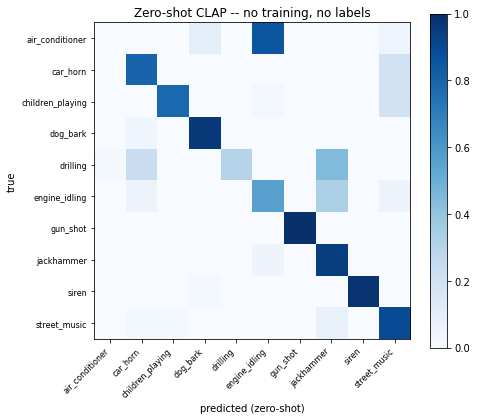

In [13]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(true, pred, normalize="true")

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(CLASSES))); 
ax.set_xticklabels(CLASSES, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(len(CLASSES))); 
ax.set_yticklabels(CLASSES, fontsize=8)
ax.set_xlabel("predicted (zero-shot)"); 
ax.set_ylabel("true")
ax.set_title("Zero-shot CLAP -- no training, no labels")
plt.colorbar(im); 
plt.tight_layout(); 
plt.show()

In [14]:
# Does the prompt template matter? Test three.
for tmpl in ["{}", "the sound of {}", "this is a sound of {}"]:    
    P = embed_text([tmpl.format(c.replace("_", " ")) 
                    for c in CLASSES])    
    a = ((E @ P.T).argmax(axis=1) == true).mean()    
    print(f'{a:.1%}   template: "{tmpl}"')

72.5%   template: "{}"
71.2%   template: "the sound of {}"
72.5%   template: "this is a sound of {}"


**Bare labels underperform sentences.** 
This is prompt engineering, and it is real — the text tower never saw isolated nouns during training, it saw captions. **But keep this in perspective:** a supervised classifier fine-tuned on UrbanSound8K (Lab 5) beats this comfortably. Zero-shot's value is not accuracy — it is that the class list can be **changed at run time**, with no retraining and no labelled data.

## 7. CLAP vs YAMNet on audio-to-audio

Here is a result that surprises people. For **audio-to-audio** retrieval — where no text is involved at run time at all — CLAP's audio tower still tends to beat YAMNet. Why? Because CLAP's audio space was *organised by* text supervision during training. It is semantically arranged, not merely acoustically arranged.

In [15]:
def eval_a2a(X, K=10, n_queries=200):    
    N = len(X)    
    qs = np.random.choice(N, min(n_queries, N), replace=False)    
    precs = []    
    for i in qs:        
        s = X @ X[i]; s[i] = -np.inf        
        ranked = np.argsort(-s)[:K]        
        precs.append((label_ids[ranked] == label_ids[i]).mean())    
    return np.mean(precs)

p_clap = eval_a2a(E)
print(f"Precision@10, audio->audio:")
print(f"  CLAP audio tower : {p_clap:.3f}")
print()
print("Re-run Lab 6A's evaluate() on its YAMNet matrix to compare directly.")
print("Typically CLAP wins -- text supervision organised the space semantically.")

Precision@10, audio->audio:
  CLAP audio tower : 0.850

Re-run Lab 6A's evaluate() on its YAMNet matrix to compare directly.
Typically CLAP wins -- text supervision organised the space semantically.


## 8. Making it fail — compositionality

The slides claimed CLAP behaves close to a **bag of sound events**: it registers *what* ispresent, but not *in what order*.Let us try to break it on purpose.

In [16]:
pairs = [("a dog barks and then a siren wails",  "a siren wails and then a dog barks"),    
         ("a jackhammer with no music playing",  "a jackhammer with music playing"),    
         ("two dogs barking", "one dog barking"),]
for a_txt, b_txt in pairs:    
    va, vb = embed_text([a_txt])[0], embed_text([b_txt])[0]    
    print(f"sim = {float(va @ vb):.4f}")    
    print(f'   A: "{a_txt}"')    
    print(f'   B: "{b_txt}"')    
    print()

sim = 0.9906
   A: "a dog barks and then a siren wails"
   B: "a siren wails and then a dog barks"

sim = 0.7786
   A: "a jackhammer with no music playing"
   B: "a jackhammer with music playing"

sim = 0.9388
   A: "two dogs barking"
   B: "one dog barking"



**Read the numbers.** 

These sentence pairs mean *opposite* things — reversed order,negated, different counts — yet CLAP places them almost on top of each other.
This is not a bug to be tuned away. It is structural:
- CLAP's output is **one number**, a similarity score.
- A single scalar cannot count, cannot order, cannot negate, cannot explain.
- It can **rank**. It cannot **reason**.

To ask *"how many times does the dog bark, and does it happen before or after the car?"*
we need a model that **generates language** conditioned on audio.
**That is Lab 8C.**